# Point mutants: a protein as the sample

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/igbaskin/cmf-qsar/blob/main/docs/tutorials/24_point_mutants.ipynb)

In every earlier notebook the sample is a small molecule. Here the sample is a **variant of one
protein**. A **point mutant** is a protein in which one amino acid is replaced by another. The
number to predict is the change of the **folding stability**: ddG, in kcal/mol, is the unfolding
free energy of the variant minus that of the wild type, the protein as found in nature. A negative
ddG means that the substitution makes the protein less stable.

A variant keeps the backbone of the wild type, so there is nothing to superimpose. The backbone of
the changed residue also gives a frame by rule: the origin at the alpha carbon, the first axis
along the bond to the nitrogen, the plane through the carbonyl carbon. In that frame a change at
one position can be compared with a change at another, and one model covers every position.

The notebook asks one question. **Does a field description of the change, or of the surroundings
of the changed residue, predict ddG better than a count of the atoms around the residue?** The
count is the simplest measure of burial, which means how deep in the protein a residue lies. It
is the reference that every such model has to beat, and the notebook measures it.

1. It reads the data: four small domains and 5,246 measured substitutions.
2. It builds one mutant and looks at what the field of a change is.
3. It counts how well three cheap descriptions predict ddG with whole positions, stretches of
   the chain and proteins held out.
4. It measures the field of the surroundings against a count, with a nonlinear model for both.
5. It reads the stored measurement of the field of the change, which needs 657 built structures.

Running time: about four minutes.

In [1]:
# Run this cell first. On Google Colab it fetches the repository and installs the package;
# on a local checkout it only moves to the repository root, so that the example paths work.
import os, subprocess, sys

if "google.colab" in sys.modules:
    if not os.path.exists("cmf-qsar"):
        subprocess.run(["git", "clone", "-q", "https://github.com/igbaskin/cmf-qsar.git"], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "./cmf-qsar", "py3Dmol"], check=True)
    os.chdir("cmf-qsar")
else:
    while not os.path.exists("pyproject.toml") and os.path.dirname(os.getcwd()) != os.getcwd():
        os.chdir("..")
print("working in", os.getcwd())

working in C:\Users\baski\work\claude\cmf


This notebook builds a protein structure with **OpenMM** (a molecular mechanics program) and
**PDBFixer** (which completes a structure and adds hydrogens). Both install with
`pip install openmm pdbfixer`. They are not part of `cmfqsar[tutorials]`, so the next cell checks
for them. On Google Colab it installs them, which takes about a minute.

In [2]:
try:
    import openmm, pdbfixer
except ImportError:
    if "google.colab" in sys.modules:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "openmm", "pdbfixer"], check=True)
    else:
        raise ImportError("this notebook needs OpenMM and PDBFixer: pip install openmm pdbfixer")
print("OpenMM and PDBFixer are available")

OpenMM and PDBFixer are available


## The data

The files are in `examples/mutants/`: one folder for each of four natural domains, named by their
Protein Data Bank code. Each holds the structure of the wild type (an AlphaFold model, from the
same source as the labels), the sequence, and a table of the measured substitutions. The labels
come from the mega-scale stability experiment of Tsuboyama and colleagues (Nature 2023, data under
the licence CC BY 4.0). `examples/mutants/README.md` says what was kept and what was left out.

In [3]:
import os
import sys

os.environ["CMF_KERNEL_CACHE"] = "0"
sys.path.insert(0, "benchmarks")

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import spearmanr

import run_mutants as mu                # the tables, folds, kernels and fits of this series
from cmfqsar import mutants as MU

tables = {d: mu.read_table(d) for d in mu.DOMAINS}
print("%-6s %9s %14s %12s %10s %8s %22s" % ("domain", "residues", "substitutions", "positions", "mean ddG", "sd", "share between positions"))
all_ddg, all_site = [], []
for d, rows in tables.items():
    info = dict(line.split()[:2] for line in open(os.path.join(mu.EXAMPLES, d, "wild_type.txt")) if line.strip())
    ddg = np.array([float(r["ddG_ML"]) for r in rows])
    site = np.array([int(r["position"]) for r in rows])
    means = {p: ddg[site == p].mean() for p in set(site)}
    within = sum(((ddg[site == p] - means[p]) ** 2).sum() for p in means)
    share = 1 - within / ((ddg - ddg.mean()) ** 2).sum()
    print("%-6s %9d %14d %12d %10.2f %8.2f %22.2f" % (d, len(info["sequence"]), len(rows), len(means), ddg.mean(), ddg.std(), share))
    all_ddg += list(ddg)
    all_site += [(d, p) for p in site]
print("all four: %d substitutions, mean %.2f, standard deviation %.2f kcal/mol" % (len(all_ddg), np.mean(all_ddg), np.std(all_ddg)))

domain  residues  substitutions    positions   mean ddG       sd share between positions
1O6X          72           1356           72      -0.81     1.16                   0.59
1UFM          72           1353           72      -0.83     1.07                   0.63
2K5N          67           1236           67      -1.37     1.50                   0.70
3ZGK          69           1301           69      -0.93     1.06                   0.66
all four: 5246 substitutions, mean -0.97, standard deviation 1.23 kcal/mol


The mean ddG is below zero in every domain: the average substitution lowers the stability. The
last column is the share of the variance of ddG that lies between positions, from 59 % to 70 %.
It is not a model, because it uses the measured values of each position. It says that most of
ddG is a property of where the residue sits, and the rest is a property of what it is replaced
by and of noise.

## One mutant, and the field of its change

The wild-type structure is completed and given hydrogens by PDBFixer, and every atom gets a
charge from the Amber force field. `build_mutant` then replaces one residue, starts the new side
chain from six turns of its first torsion, relaxes it and the side chains of its neighbours with
OpenMM, and keeps the lowest-energy structure that is a sound one. The example is leucine 6 of
domain 1O6X, the position with the most atoms around it, replaced by alanine. This builds one
structure in a few seconds. A full series of thousands needs hours, which is why the notebook
builds only this one.

In [4]:
import tempfile
from cmfqsar.fields import FieldSet, build_fields
from cmfqsar.localenv import difference_field

domain = "1O6X"
work = tempfile.mkdtemp()
wild_pdb = os.path.join(work, "wild_type.pdb")
wild = MU.prepare_wild_type(os.path.join(mu.EXAMPLES, domain, domain + ".pdb"), wild_pdb)
wild_mol = MU.protein_of(wild)
field_set = FieldSet.create(charge_model="file")          # the charges come from the force field
wild_fields = build_fields(wild_mol, field_set, name="wild type")
print("wild type: %d atoms, %d residues" % (wild_mol.GetNumAtoms(), len({a.GetPDBResidueInfo().GetResidueNumber() for a in wild_mol.GetAtoms()})))

change = MU.Mutation.parse("L6A")
row = next(r for r in tables[domain] if r["label"] == change.label)
mutant = MU.build_mutant(wild_pdb, change)
mutant_mol = MU.protein_of(mutant)
mutant_fields = build_fields(mutant_mol, field_set, name=change.label)
print("%s: measured ddG %.2f kcal/mol" % (change.label, float(row["ddG_ML"])))
print("force field energy before and after relaxing the new side chain: %.0f and %.0f kJ/mol; starting turns that collapsed: %d of 6" % (
    mutant.energy_before, mutant.energy_after, mutant.collapsed))
print("closest two atoms in the mutant: %.2f A (a structure below %.1f A is refused)" % (
    MU.closest_approach(np.array(mutant_mol.GetConformer().GetPositions())), MU.MIN_SEPARATION))
print("largest move of a backbone atom outside the changed residue: %.3f A" % MU.frame_shift(mutant_mol, wild_mol, change.position))

old = MU.side_chain_field(wild_fields, wild_mol, change.position)
new = MU.side_chain_field(mutant_fields, mutant_mol, change.position)
diff = difference_field(new, old, name=change.label)
print("side chain atoms: wild type %d, mutant %d; the difference field holds %d (the new ones with weight +1, the old ones with -1)" % (
    old.n_atoms, new.n_atoms, diff.n_atoms))

wild type: 1141 atoms, 72 residues


L6A: measured ddG -2.80 kcal/mol
force field energy before and after relaxing the new side chain: -3570 and -3948 kJ/mol; starting turns that collapsed: 0 of 6
closest two atoms in the mutant: 0.96 A (a structure below 0.7 A is refused)
largest move of a backbone atom outside the changed residue: 0.000 A
side chain atoms: wild type 15, mutant 6; the difference field holds 21 (the new ones with weight +1, the old ones with -1)


The difference field is the new side chain minus the old one, both in the frame of the backbone.
Everything else cancels, because the backbone of the rest of the protein was held fixed. The
backbone check above prints zero. The next picture shows the two side chains in that frame.

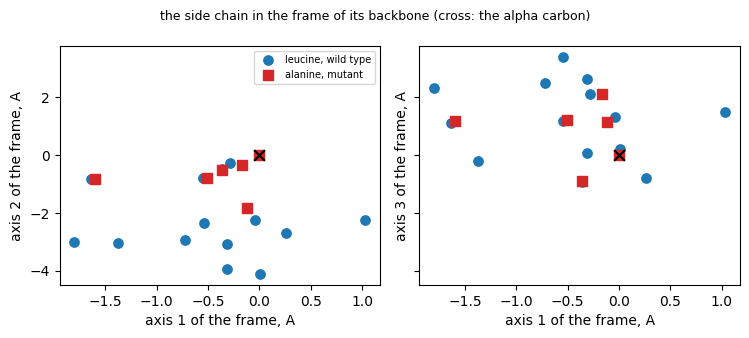

In [5]:
xyz_old, xyz_new = np.asarray(old.coords), np.asarray(new.coords)
fig, axes = plt.subplots(1, 2, figsize=(7.6, 3.4), sharex=True, sharey=True)
for ax, (a, b) in zip(axes, ((0, 1), (0, 2))):
    ax.scatter(xyz_old[:, a], xyz_old[:, b], s=45, color="tab:blue", label="leucine, wild type")
    ax.scatter(xyz_new[:, a], xyz_new[:, b], s=45, color="tab:red", marker="s", label="alanine, mutant")
    ax.scatter([0], [0], s=60, color="black", marker="x")
    ax.set_xlabel("axis %d of the frame, A" % (a + 1))
    ax.set_ylabel("axis %d of the frame, A" % (b + 1))
axes[0].legend(fontsize=7, loc="best")
plt.suptitle("the side chain in the frame of its backbone (cross: the alpha carbon)", fontsize=9)
plt.tight_layout()
plt.show()

## Samples without a built mutant

A full measurement of the difference field needs a built structure for every substitution. The
benchmark `run_mutants.py` built 657 of them, and keeps them out of the repository (about
90 MB with their fields). The notebook uses what the repository holds, which is the wild type and the table of
labels, for a second question that needs no mutant: **does the surroundings of a position
predict ddG better than a count of atoms?**

`site_contexts` gives the surroundings of every position: all the atoms of the wild type around
the alpha carbon, without the side chain that is replaced, in the frame of the residue, under a
Gaussian envelope. The same surroundings belong to every substitution at that position. Four
substitutions of each position are drawn with a fixed seed. A position is kept whole, because a
position is what the folds hold out.

1120 substitutions at 280 positions; 840 contexts held in all
atoms around a site at the envelope used here: from 39 to 356, median 214


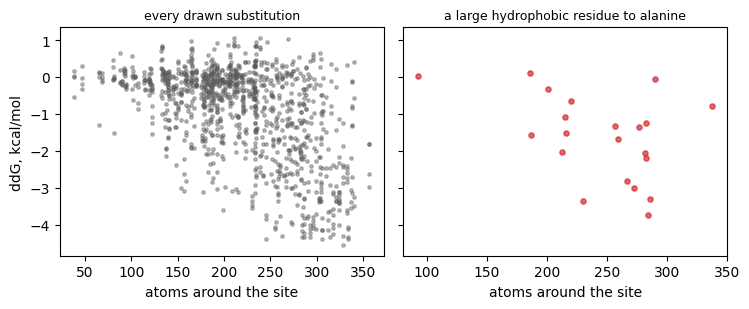

rank correlation of ddG with the atoms around the site: -0.46 for all 1120, -0.37 for the 21 substitutions of a large hydrophobic residue to alanine


In [6]:
contexts = mu.site_contexts()
draw = mu.SiteSamples(contexts, mu.DOMAINS, 4, 0)
count = np.array([contexts[(mu.SITE_RHO, d, p)].n_atoms for d, p in zip(draw.domain, draw.position)])
print("%d substitutions at %d positions; %d contexts held in all" % (len(draw), len(set(zip(draw.domain, draw.position))), len(contexts)))
print("atoms around a site at the envelope used here: from %d to %d, median %d" % (count.min(), count.max(), np.median(count)))

large = [m.wild in "FILMVWY" and m.new == "A" for m in draw.mutation]
fig, axes = plt.subplots(1, 2, figsize=(7.6, 3.2), sharey=True)
axes[0].scatter(count, draw.y, s=6, alpha=0.4, color="0.35")
axes[0].set_title("every drawn substitution", fontsize=9)
axes[1].scatter(count[large], draw.y[large], s=14, alpha=0.7, color="tab:red")
axes[1].set_title("a large hydrophobic residue to alanine", fontsize=9)
for ax in axes:
    ax.set_xlabel("atoms around the site")
axes[0].set_ylabel("ddG, kcal/mol")
plt.tight_layout()
plt.show()
rho = spearmanr(count, draw.y)[0]
print("rank correlation of ddG with the atoms around the site: %+.2f for all %d, %+.2f for the %d substitutions of a large hydrophobic residue to alanine" % (
    rho, len(draw), spearmanr(count[large], draw.y[large])[0], sum(large)))

A substitution costs more (ddG is more negative) where more atoms surround the residue. The rank
correlation is -0.46 for all drawn substitutions, and -0.37 for the 21 changes of a large
hydrophobic residue to alanine, a small set. The question is not whether burial matters, but
whether a field description reads anything about the site that a count of atoms does not.

## What holding out a position means

A model of a site is tested on sites it has not seen. If one residue is held out, its neighbours
along the chain stay in the training part, and their surroundings share most of the atoms of the
held-out site. The next check counts it. For two positions of one domain it gives the share of
atoms that the surroundings have in common.

In [7]:
shared = {}
for gap in (1, 2, 4, 9, 20):
    values = []
    for d in mu.DOMAINS:
        positions = sorted(p for (r, dd, p) in contexts if r == mu.SITE_RHO and dd == d)
        sets = {p: set(int(i) for i in contexts[(mu.SITE_RHO, d, p)].member_atom_map) for p in positions}
        for p in positions:
            if p + gap in sets:
                values.append(len(sets[p] & sets[p + gap]) / len(sets[p] | sets[p + gap]))
    shared[gap] = np.mean(values)
    print("positions %2d apart along the chain share %3.0f %% of the atoms of their surroundings (%d pairs)" % (gap, 100 * shared[gap], len(values)))

positions  1 apart along the chain share  57 % of the atoms of their surroundings (276 pairs)
positions  2 apart along the chain share  43 % of the atoms of their surroundings (272 pairs)
positions  4 apart along the chain share  30 % of the atoms of their surroundings (264 pairs)
positions  9 apart along the chain share  11 % of the atoms of their surroundings (244 pairs)
positions 20 apart along the chain share   8 % of the atoms of their surroundings (200 pairs)


The share is the number of atoms in both surroundings divided by the number in either. Residues
next to each other share 57 % of their atoms. The share is 43 % at two residues apart, 30 % at
four, and 11 % at nine. So the notebook uses three ways to hold out.

- **Positions:** every substitution at one position is in the same fold. Neighbours still help.
- **Segments:** nine consecutive residues at a time, which removes the neighbours too. Residues
  that are far apart along the chain and close in space are still split. At nine apart the share
  has fallen to 11 %.
- **Domains:** one whole protein at a time. This is the case that a user of such a model needs.

The ridge, the kernel width and the mixing weights are chosen on inner folds of the same kind,
inside the training part. A difference of q2 has a 95 % bootstrap interval over the held-out
unit. The q2 is the share of the variance of the held-out ddG that the model explains, as in the
earlier notebooks.

## The cheap references

Three descriptions need no field. The mean of the training part has q2 = 0 by construction. A
linear regression on three columns of the **substitution**, the change of residue volume, of
hydropathy and of formal charge, knows nothing about the site. A linear regression on **burial**
adds the number of atoms around the site, counted at three envelope widths, and the sum of the
envelope factors, which is a soft count: six columns, with the three of the substitution.

In [8]:
seeds = [0, 1, 2]
X_sub, _ = MU.substitution_features(draw.mutation)
X_three = X_sub[:, :3]
X_burial = mu.burial_rows(draw)
print("%d samples; %d substitution columns, %d burial columns with them" % (len(draw), X_three.shape[1], X_burial.shape[1]))
cheap = {}
print("%-12s %30s %10s %10s %10s" % ("", "", "positions", "segments", "domains"))
for by in ("position", "segment", "domain"):
    tg = draw.targets(by)
    n_groups = int(tg.molecule.max()) + 1
    folds = min(mu.FOLDS, n_groups) if by != "domain" else 4
    cheap[by] = {"mean": mu.mean_reference(tg, seeds, folds)[0],
                 "three": mu.regression(X_three, tg, seeds, "three", folds)[0],
                 "burial": mu.regression(X_burial, tg, seeds, "burial", folds)[0]}
    cheap[by]["tg"] = tg
names = [("mean", "the mean of the training part"), ("three", "three substitution columns"),
         ("burial", "burial and the three columns")]
for key, label in names:
    cells = []
    for by in ("position", "segment", "domain"):
        y = np.asarray(cheap[by]["tg"].y, float)
        cells.append("%+.3f" % mu.B.repeated_q2(cheap[by][key], y)[0])
    print("%-44s %10s %10s %10s" % (label, *cells))
print()
for by in ("position", "segment", "domain"):
    d_, lo, hi = mu.B.paired_repeats(cheap[by]["burial"], cheap[by]["three"], cheap[by]["tg"])
    print("burial minus the three columns, %ss held out: %+.3f [%+.3f, %+.3f]" % (by, d_, lo, hi))

1120 samples; 3 substitution columns, 9 burial columns with them
                                             positions   segments    domains
the mean of the training part                    -0.005     -0.004     -0.019
three substitution columns                       +0.192     +0.194     +0.177
burial and the three columns                     +0.346     +0.338     +0.314



burial minus the three columns, positions held out: +0.154 [+0.096, +0.208]


burial minus the three columns, segments held out: +0.144 [+0.084, +0.200]
burial minus the three columns, domains held out: +0.137 [+0.015, +0.207]


Read the first column of the table as the rule: a regression that knows how many atoms surround
the site is far ahead of one that knows only the substitution. Burial is a large part of what a
substitution costs. The other two hold-outs give the same order. The numbers fall a little when
whole domains are held out.

## The surroundings as a field, against the count

The first version of the burial reference above is linear. A field kernel is not, so the next
step gives the count the same chance. Every kernel on columns below is a Gaussian,
exp(-d² / 2k), of the standardised columns, where k is the number of columns. The width is fixed
by this rule and not searched. The notebook checks later that doubling or halving it changes
nothing that matters.

- **Columns kernel:** the three substitution columns alone.
- **Burial kernel:** one count, the atoms inside the envelope, with the three columns.
- **Burial kernel, all columns:** the six burial numbers with the three columns.
- **Context:** the field kernel of the surroundings of the site, at one envelope, and nothing else.
  It is the same for every substitution at a position.
- **Joined:** the Gaussian kernel on the three columns plus the field kernel of the surroundings,
  with the weight of the second chosen on the inner folds. The first stage of the benchmark joins
  the *difference field* with the surroundings. The difference field equals the three columns in
  that stage, so the columns stand in for it here.

The field kernel of the surroundings is the slow step, between one and two and a half minutes for
280 positions. The cell then fits every description with whole positions held out and three
repeats of the folds, which takes about a minute.

In [9]:
import time
t0 = time.time()
keys, K_position = mu.position_kernel(contexts)
print("the kernel of the surroundings of %d positions: %.0f s" % (len(keys), time.time() - t0))
K_draw = mu.expand_position_kernel(keys, K_position, draw)
t0 = time.time()
live = mu.site_rows(draw, K_draw, seeds, ("position",))["position"]
print("the fits: %.0f s" % (time.time() - t0))
print()
print("%-92s %8s %8s" % ("positions held out, three repeats of ten folds", "q2", "RMSE"))
for name in mu.SITE_ORDER:
    r = live["rows"][name]
    print("%-92s %+8.3f %8.3f" % (mu.SITE_LABEL[name], r["q2"], r["rmse"]))
print()
print("%-62s %s" % ("difference of q2, with the 95 % interval over positions", ""))
for key, val in live["differences"].items():
    print("%-62s %s" % (key, mu._iv(val)))

the kernel of the surroundings of 280 positions: 85 s


the fits: 50 s

positions held out, three repeats of ten folds                                                     q2     RMSE
the mean of the training part                                                                  -0.005    1.243
linear regression on the change of residue volume, hydropathy and charge                       +0.192    1.115
linear regression on six burial numbers and the three columns                                  +0.346    1.003
Gaussian kernel on the three columns                                                           +0.247    1.076
Gaussian kernel on one burial count and the three columns                                      +0.458    0.913
Gaussian kernel on the six burial numbers and the three columns                                +0.472    0.901
the surroundings of the site as a field kernel                                                 +0.189    1.117
Gaussian kernel on the three columns, joined with the field kernel of the surroundings         +

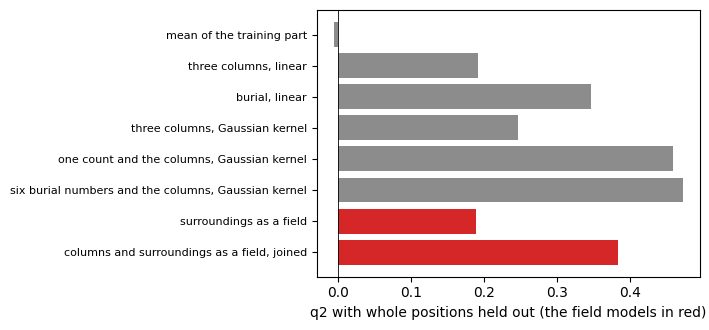

In [10]:
order = list(mu.SITE_ORDER)
short = {"mean": "mean of the training part", "three columns": "three columns, linear",
         "burial": "burial, linear", "columns kernel": "three columns, Gaussian kernel",
         "burial kernel": "one count and the columns, Gaussian kernel",
         "burial kernel, all columns": "six burial numbers and the columns, Gaussian kernel",
         "context": "surroundings as a field", "joined": "columns and surroundings as a field, joined"}
colour = {"context": "tab:red", "joined": "tab:red"}
fig, ax = plt.subplots(figsize=(7.2, 3.4))
y = np.arange(len(order))[::-1]
ax.barh(y, [live["rows"][n]["q2"] for n in order], color=[colour.get(n, "0.55") for n in order])
ax.set_yticks(y)
ax.set_yticklabels([short[n] for n in order], fontsize=8)
ax.axvline(0, color="black", lw=0.6)
ax.set_xlabel("q2 with whole positions held out (the field models in red)")
plt.tight_layout()
plt.show()

Four things stand out in the table.

- **A Gaussian kernel on one count and the three columns reaches q² 0.458.** The linear model of
  the same numbers reaches 0.346, so the nonlinear model of burial adds +0.112 [+0.075, +0.153].
  The linear reference of the first stage understates what a count can do.
- **The field of the surroundings alone is worse than the count.** It reaches 0.189, below the
  linear burial regression, and far below the Gaussian kernel on the count.
- **Joined with the columns, the field reaches 0.383, and the count is ahead of it** by
  +0.075 [+0.013, +0.139] (burial kernel minus joined). The interval excludes zero. The field
  does add to the columns kernel, by +0.136 [+0.079, +0.192], but the count adds more.
- **Giving the count six numbers instead of one gains nothing that the interval shows.** The
  six-number kernel is ahead by 0.014, and the interval of that difference holds zero (-0.012
  to +0.040). One count is enough.

The check of the width, and the other two ways to hold out, are in the stored result below.

## The stored measurements

The same second stage, for two draws of the substitutions and the three ways to hold out, is in
`benchmarks/results/mutants/sites.json` (about 10 minutes of running, with the kernel made once).
The notebook reads it.

In [11]:
import json
with open("benchmarks/results/mutants/sites.json", encoding="utf-8") as fh:
    stored = json.load(fh)
show = ("burial kernel - burial", "joined - columns kernel", "joined - burial kernel")
for draw_key, part in stored["draws"].items():
    print("draw %s: %d substitutions at %d positions" % (draw_key, part["n"], part["n_positions"]))
    print("  %-44s %12s %12s %12s" % ("q2", "positions", "segments", "domains"))
    for name in ("three columns", "burial", "columns kernel", "burial kernel", "context", "joined"):
        cells = ["%+.3f" % part["holdout"][by]["rows"][name]["q2"] for by in ("position", "segment", "domain")]
        print("  %-44s %12s %12s %12s" % (short[name], *cells))
    for key in show:
        cells = [mu._iv(part["holdout"][by]["differences"][key]) for by in ("position", "segment", "domain")]
        print("  %-44s %s" % (key, "   ".join(cells)))
    print()
check = stored["draws"]["0"]["width_check"]
print("width of the kernels on columns, draw 0, positions held out (the rule is 1.0)")
for name in ("columns kernel", "burial kernel", "burial kernel, all columns", "joined"):
    cells = ["%+.3f" % check["rows"][name + ("" if w == 1.0 else " at %s times the width" % w)]["q2"] for w in stored["widths"]]
    print("  %-44s %s" % (short[name], "   ".join("x%s %s" % (w, c) for w, c in zip(stored["widths"], cells))))

draw 0: 1120 substitutions at 280 positions
  q2                                              positions     segments      domains
  three columns, linear                              +0.192       +0.194       +0.177
  burial, linear                                     +0.346       +0.338       +0.314
  three columns, Gaussian kernel                     +0.247       +0.246       +0.233
  one count and the columns, Gaussian kernel         +0.458       +0.450       +0.428
  surroundings as a field                            +0.189       +0.186       +0.126
  columns and surroundings as a field, joined        +0.383       +0.381       +0.335
  burial kernel - burial                       +0.112 [+0.075, +0.153]   +0.112 [+0.070, +0.160]   +0.113 [+0.071, +0.187]
  joined - columns kernel                      +0.136 [+0.079, +0.192]   +0.135 [+0.086, +0.179]   +0.102 [+0.072, +0.143]
  joined - burial kernel                       -0.075 [-0.139, -0.013]   -0.069 [-0.139, -0.005]   -0.093 [-

The order is the same on both draws and with all three ways to hold out: the Gaussian kernel on
a count is ahead of the field of the surroundings joined with the same columns, and the interval of
the difference excludes zero in every one of the six cells. The width of the kernels changes the
q² by 0.011 at most, and with the width halved or doubled the count is still ahead of the joined
field, with an interval that excludes zero.

## The field of the change itself, which needs built structures

The notebook did not build the difference field of the 5,246 substitutions. The benchmark built
657 of them, at 174 positions, with four substitutions of each position, and measured the
difference field of the change itself, the field of the surroundings, and the two joined. The
saved result is read here.

In [12]:
with open("benchmarks/results/mutants/mutants.json", encoding="utf-8") as fh:
    first = json.load(fh)
print("%d substitutions at %d positions of %d domains (the ones that have a built structure); ddG sd %.2f kcal/mol" % (
    first["n"], first["n_positions"], len(first["domains"]), first["sd_y"]))
labels = {"three columns": "three substitution columns", "burial": "burial and the three columns, linear",
          "new": "the new side chain alone", "difference": "difference field",
          "context": "surroundings as a field",
          "difference+context": "difference field and surroundings, joined"}
print("%-46s %12s %12s %12s" % ("q2", "positions", "segments", "domains"))
for name, label in labels.items():
    cells = ["%+.3f" % first["holdout"][by]["rows"][name]["q2"] for by in ("position", "segment", "domain")]
    print("%-46s %12s %12s %12s" % (label, *cells))
for key in ("difference - three columns", "new - difference", "difference+context - three columns", "difference+context - burial", "burial - three columns"):
    cells = [mu._iv(first["holdout"][by]["differences"][key]) for by in ("position", "segment", "domain")]
    print("%-46s %s" % (key, "   ".join(cells)))
agree = first["agreement"]["difference"]
print()
print("mean kernel of two difference fields of the same substitution at other positions (%d pairs): %+.3f" % (
    agree["pairs with the same substitution"], agree["same substitution, other position"]))

657 substitutions at 174 positions of 4 domains (the ones that have a built structure); ddG sd 1.23 kcal/mol
q2                                                positions     segments      domains
three substitution columns                           +0.181       +0.174       +0.158
burial and the three columns, linear                 +0.300       +0.262       +0.156
the new side chain alone                             +0.065       +0.069       +0.055
difference field                                     +0.156       +0.148       +0.139
surroundings as a field                              +0.190       +0.148       +0.051
difference field and surroundings, joined            +0.311       +0.291       +0.141
difference - three columns                     -0.025 [-0.072, +0.025]   -0.027 [-0.062, +0.006]   -0.019 [-0.071, +0.036]
new - difference                               -0.091 [-0.169, -0.008]   -0.079 [-0.133, -0.022]   -0.084 [-0.137, -0.028]
difference+context - three columns         

The difference field is not shown to predict better than the three columns (the difference is
-0.025 with positions held out, and its interval holds zero). The new side chain alone is worse
than the change. Joined with the field of the surroundings, the difference field is ahead of the
columns by +0.130 with positions held out. That looks like a success of the field. But the
linear regression on the count of atoms is equal to it in this stage (+0.011 [-0.086, +0.111]),
and the second stage, on every position, shows a nonlinear model of the count ahead of a field
joined in the same way. The second stage did not use the difference field, which needs built
structures, so the two stages are linked by the columns that equal it.

## What the notebook shows, and what it does not

- **Burial is the main thing a model of stability needs.** One number, the atoms around the
  site, with the three columns of the substitution, explains about a third of the variance of
  ddG with whole positions held out, and with a nonlinear model about 0.46.
- **A field of the surroundings, as built here, is worth less than that count.** The field
  alone reaches 0.19, and joined with the columns 0.38, with the interval of the loss clear of
  zero on both draws and all three ways to hold out.
- **A field of the change is not shown to be worth more than the three columns of the
  substitution.** The change is the right sample: in the first stage the new side chain alone is
  worse than the change.
- **The check before the model matters.** The first stage called the joined description a gain
  of +0.130 over the substitution columns. The reference that it had to meet, a count with a
  linear model, equalled it. A count with a nonlinear model is ahead of a field joined in the
  same way.

What it does not show.

- It does not show that no field of a site can beat a count. It tried one field of the
  surroundings, at one envelope, cosine-normalised. A cosine-normalised kernel divides out the
  size of the field, and the number of atoms is a size. Whether that is the reason was not tested.
  Typed fields, directions and the solvent-accessible area are the plan item PP3.
- It does not show how a model does on a protein it has not seen beyond four domains. The
  intervals with domains held out come from four folds.
- It does not show how the difference field does on all substitutions, because 657 structures is
  what has been built.
- The data are one experiment, with its own noise and its own definition of stability.